## Note

This notebook assumes familiarity with the `numpy` and `pandas` libraries. If you are not familiar with these libraries, you can find a notebook introducing them [here](https://drive.google.com/file/d/1VhK6F1j0jvTbWTSu4cLx_aHrl6B3mWt7/view?usp=drive_link) and the corresponding lecture (given for the Neural Networks course) [here](https://unito.webex.com/recordingservice/sites/unito/recording/7c137497f8164bb1bfd6097feab48299/playback).

## Exercise 1: Exploring Overfitting and Underfitting (Scikit-learn, Numpy, Matplotlib)

This exercise is based on the discussion of *overfitting* and *underfitting* in `02-ModelSelection.pdf`. You will visualize how model complexity affects performance on training and validation data.

**Goal:** See the bias-variance trade-off in action.

**Tasks:**
1.  Generate a synthetic dataset. Create a 1D non-linear function (e.g., `y = sin(x)`) and add some random noise to the `y` values.
2.  Split your data into a training set and a test set using `sklearn.model_selection.train_test_split`.
3.  Create a loop that fits polynomial regression models of increasing complexity (from degree 1 to 20).
    *   Inside the loop, use `sklearn.preprocessing.PolynomialFeatures` to create polynomial features, followed by `sklearn.linear_model.LinearRegression`.
4.  For each degree:
    *   Train the model on the training data.
    *   Calculate and store the Mean Squared Error (MSE) on both the **training set** and the **test set**.
5.  Plot the training MSE and test MSE as a function of the polynomial degree. You should see the training error continuously decrease and the test error decrease initially and then start increasing (forming a U-shape).
6.  Identify the approximate polynomial degree that represents a good trade-off (the "sweet spot" before overfitting begins).

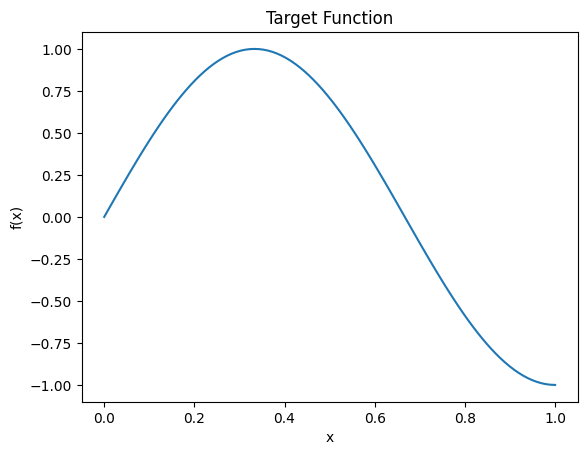

In [10]:
import numpy as np

def target_function(x):
    return np.sin(1.5* np.pi* x)

import matplotlib.pyplot as plt
x = np.linspace(0, 1, 100)
y = target_function(x)
plt.plot(x, y)
plt.title("Target Function")
plt.xlabel("x")
plt.ylabel("f(x)")
plt.show()

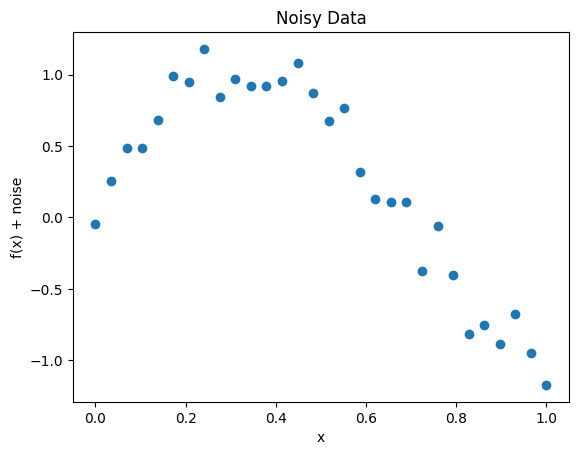

In [11]:
noise_std = 0.15

# add random gaussian noise to the target function
X = np.linspace(0, 1, 30)
y = target_function(X.flatten()) + np.random.normal(0, noise_std, size=X.shape[0])
X=X.reshape(-1, 1) #reshape for sklearn, as it expects a column vector
plt.scatter(X, y)
plt.title("Noisy Data")
plt.xlabel("x")
plt.ylabel("f(x) + noise")
plt.show()

Adesso lavoriamo sul dataset che abbiamo creato, prima creiamo il test set e il train set

In [12]:
import sklearn
X_train, X_test, y_train, y_test = sklearn.model_selection.train_test_split(X, y, test_size=0.33, random_state=42)
# create training and test sets with 33% of the data in the test set

Text(0, 0.5, 'f(x) + noise')

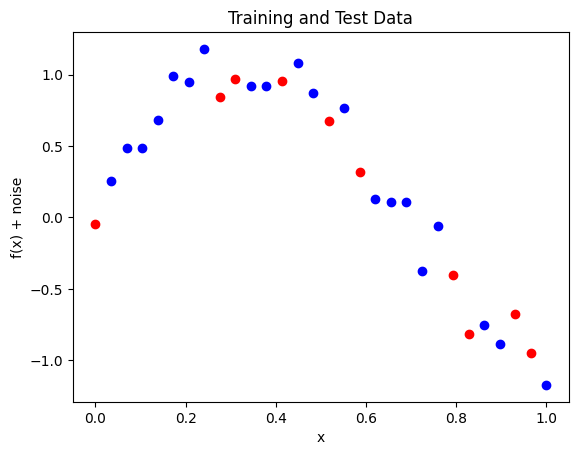

In [13]:
plt.scatter(X_train, y_train, color='blue', label='Training Data')
plt.scatter(X_test, y_test, color='red', label='Test Data')
plt.title("Training and Test Data")
plt.xlabel("x")
plt.ylabel("f(x) + noise")

In [14]:
class LeastSquares:
    def __init__(self):
        #initialize the model parameters, in this case to None
        self.coef_ = None

    def fit(self, X, y):
        # (X^T * X)^(-1) * X^T * y
        # PolynomialFeatures già include il bias term (colonna di 1), quindi non lo aggiungiamo
        #@ is the matrix multiplication operator in numpy
        #linalg.inv is the matrix inverse function in numpy
        self.coef_ = np.linalg.inv(X.T @ X) @ X.T @ y

    def predict(self, X):
        # Non aggiungiamo la colonna di 1 perché PolynomialFeatures l'ha già inclusa
        #the result is the dot product between X and the coefficients
        return X @ self.coef_

#### Plotting fitted models and data

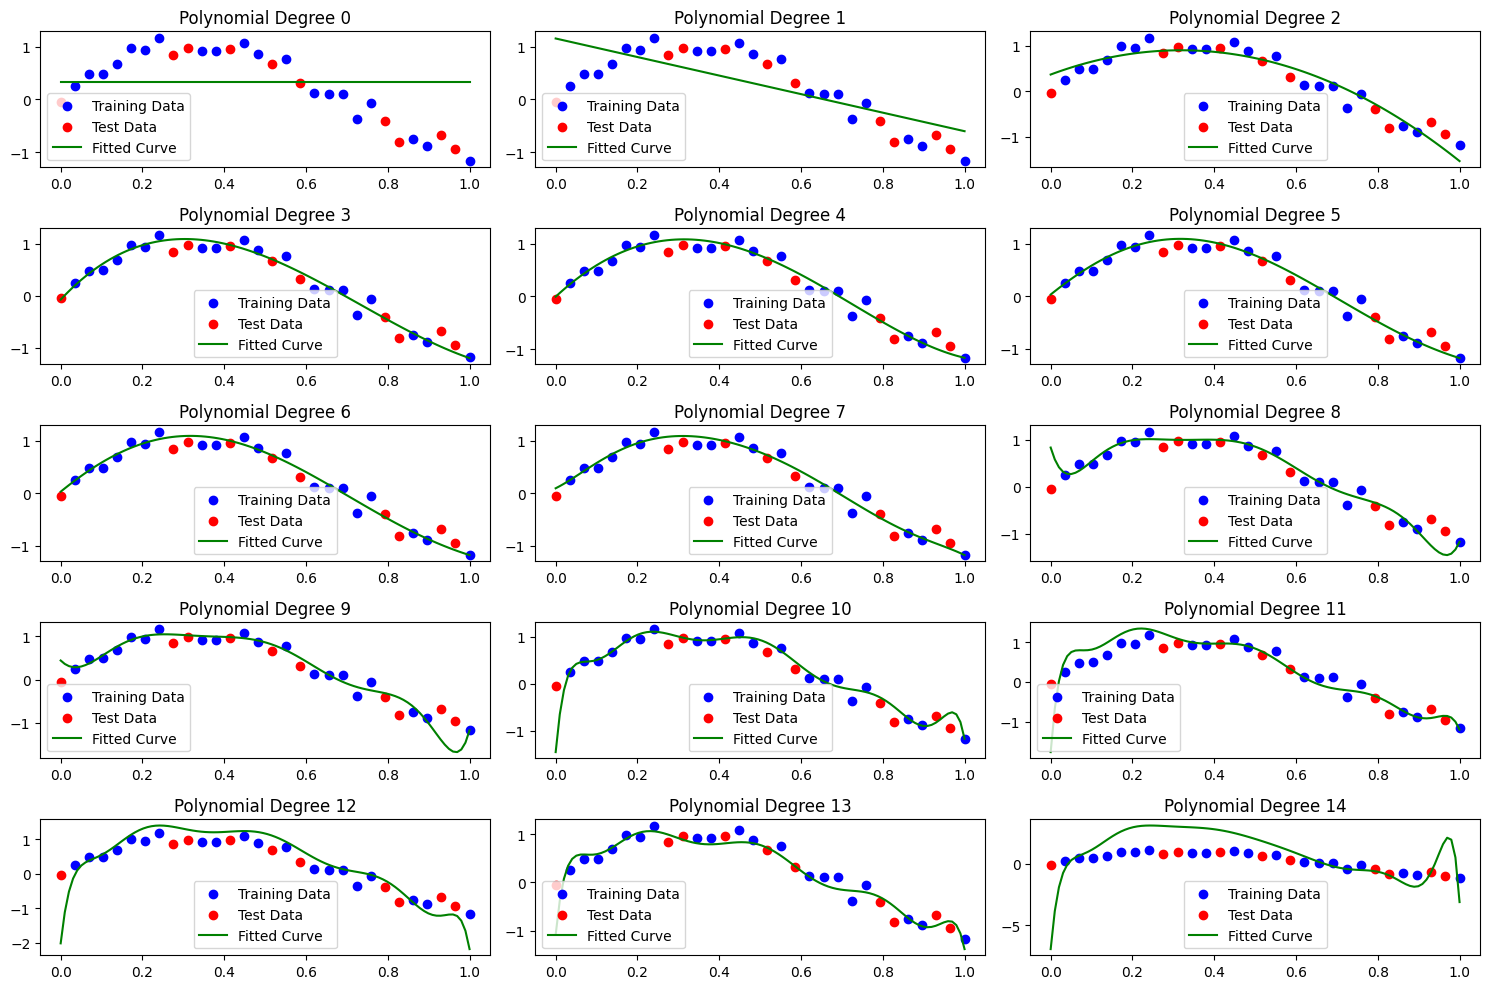

In [15]:
from sklearn.metrics import mean_squared_error

train_errors = []
test_errors = []

fig, axes = plt.subplots(5, 3, figsize=(15, 10))
axes = axes.ravel()

for degree in range(15):
    model = LeastSquares()
    poly_features = sklearn.preprocessing.PolynomialFeatures(degree=degree)
    X_train_poly = poly_features.fit_transform(X_train)
    model.fit(X_train_poly, y_train)
    train_errors.append(mean_squared_error(y_train, model.predict(X_train_poly)))
    test_errors.append(mean_squared_error(y_test, model.predict(poly_features.transform(X_test))))

    x_fit = np.linspace(0, 1, 100).reshape(-1, 1)
    y_fit = model.predict(poly_features.transform(x_fit))   
    axes[degree].scatter(X_train, y_train, color='blue', label='Training Data')
    axes[degree].scatter(X_test, y_test, color='red', label='Test Data')
    axes[degree].plot(x_fit, y_fit, color='green', label='Fitted Curve')
    axes[degree].set_title(f'Polynomial Degree {degree}')
    axes[degree].legend()   

plt.tight_layout()
plt.show()

#### Plotting train /test errors as a function of model complexity

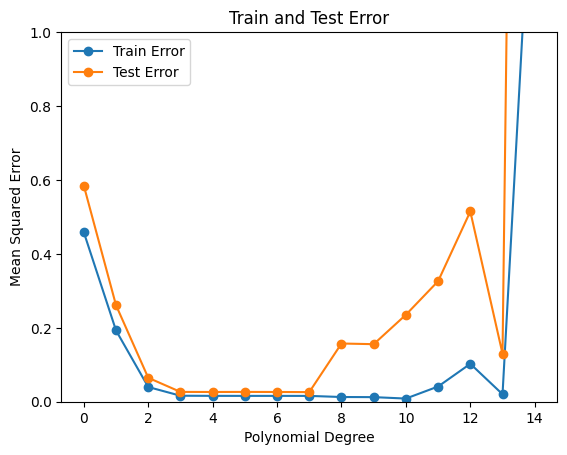

In [16]:
plt.plot(train_errors, label='Train Error', marker='o')
plt.plot(test_errors, label='Test Error', marker='o')
plt.title("Train and Test Error")
plt.xlabel("Polynomial Degree")
plt.ylabel("Mean Squared Error")
plt.ylim(0, 1)
plt.legend()
plt.show()

### Exercise 2: Model Selection and Hyperparameter Tuning (Scikit-learn)

This exercise combines several topics from `02-ModelSelection.pdf`, including *cross-validation*, *performance metrics*, and *parameter tuning*.

**Goal:** Compare different classifiers and find the best hyperparameters for a given model using a robust evaluation strategy.

**Dataset:** Use a real-world dataset from scikit-learn: the Breast Cancer dataset (`sklearn.datasets.load_breast_cancer`).

**Tasks:**
1.  Load the dataset and split it into a training set (80%) and a final test set (20%). You will not touch the test set until the very end.
2.  Choose two three different classification algorithms (`KNeighborsClassifier`, `SVC`, and `LogisticRegression`).
3.  Use `sklearn.model_selection.GridSearchCV` with 5-fold cross-validation on the **training set** to find the best hyperparameters for `SVC` and `KNeighborsClassifier`.
    *   For `SVC`, tune the `C` and `gamma` parameters.
    *   For `KNeighborsClassifier`, tune the `n_neighbors` parameter.
    *   For `LogisticRegression`, tune the `C` parameter (analogous to regularizing as it is done for Ridge regression).
4.  For each of your tuned models,  report the best cross-validated score on the training data (ideally you might want to explore more than one metric, start with the `accuracy` metric). 
5.  Select the single best model/hyperparameter combination based on your cross-validation results.
6. Report the accuracy of the models also on the test set, and compare it with the cross-validated accuracy. 

In [17]:
import sklearn.datasets
import sklearn.model_selection
import sklearn.svm
import sklearn.neighbors
import sklearn.metrics
import sklearn.linear_model
import sklearn.preprocessing
import numpy as np
import matplotlib.pyplot as plt

# Carica il dataset del cancro al seno
digits = sklearn.datasets.load_breast_cancer()
X = digits.data
y = digits.target

# Dividi in train (67%) e test (33%)
X_train, X_test, y_train, y_test = sklearn.model_selection.train_test_split(
    X, y, test_size=0.33, random_state=42
)

# IMPORTANTE: Normalizza i dati (essenziale per SVM e LogisticRegression)
scaler = sklearn.preprocessing.StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Definisci gli iperparametri da testare
C_values = [0.1, 1, 10, 100]
gamma_values = [0.0001, 0.001, 0.01, 0.1, 1]
K_values = [1, 3, 5, 7]

results = []

# Esegui grid search manuale per SVC
for C in C_values:
    for gamma in gamma_values:
        # Crea modello SVM
        svm_model = sklearn.svm.SVC(C=C, gamma=gamma)
        # Cross-validation a 5-fold, restituisce 5 score di accuracy
        cv_scores = sklearn.model_selection.cross_val_score(
            svm_model, X_train_scaled, y_train, cv=5, scoring='accuracy')

        # Addestra il modello sul training set e valuta sul test set
        svm_model.fit(X_train_scaled, y_train)
        y_pred = svm_model.predict(X_test_scaled)
        test_set_accuracy = sklearn.metrics.accuracy_score(y_test, y_pred)

        results.append(('SVC', C, gamma, None, np.mean(cv_scores), test_set_accuracy))

# Grid search per KNN
for K in K_values:
        # Crea modello KNN
        knn_model = sklearn.neighbors.KNeighborsClassifier(n_neighbors=K)
        # Cross-validation a 5-fold
        cv_scores = sklearn.model_selection.cross_val_score(
            knn_model, X_train_scaled, y_train, cv=5, scoring='accuracy')

        # Addestra e valuta il modello
        knn_model.fit(X_train_scaled, y_train)
        y_pred = knn_model.predict(X_test_scaled)
        test_set_accuracy = sklearn.metrics.accuracy_score(y_test, y_pred)

        results.append(('KNN', None, None, K, np.mean(cv_scores), test_set_accuracy))

# Grid search per LogisticRegression
for C in C_values:
    # Crea modello di regressione logistica (aumenta max_iter per convergenza)
    logreg_model = sklearn.linear_model.LogisticRegression(C=C, max_iter=5000, solver='lbfgs')
    # Cross-validation a 5-fold
    cv_scores = sklearn.model_selection.cross_val_score(
        logreg_model, X_train_scaled, y_train, cv=5, scoring='accuracy')
    
    # Addestra e valuta il modello
    logreg_model.fit(X_train_scaled, y_train)
    y_pred = logreg_model.predict(X_test_scaled)
    test_set_accuracy = sklearn.metrics.accuracy_score(y_test, y_pred)
    
    results.append(('LogReg', C, None, None, np.mean(cv_scores), test_set_accuracy))


In [18]:
import pandas as pd
df_results = pd.DataFrame(results, columns=['Model', 'C', 'Gamma', 'K', 'CV Accuracy', 'Test Set Accuracy'])

# Ordinare il DataFrame originale sul posto
df_results.sort_values('CV Accuracy', ascending=False, inplace=True)
df_results

,Model,C,Gamma,K,CV Accuracy,Test Set Accuracy
16,SVC,100.0,0.0010,NaN,0.976350,0.978723
25,LogReg,1.0,NaN,NaN,0.976350,0.978723
24,LogReg,0.1,NaN,NaN,0.973718,0.984043
12,SVC,10.0,0.0100,NaN,0.971087,0.984043
26,LogReg,10.0,NaN,NaN,0.965858,0.978723
27,LogReg,100.0,NaN,NaN,0.963295,0.941489
7,SVC,1.0,0.0100,NaN,0.963192,0.968085
23,KNN,NaN,NaN,7.0,0.960595,0.957447
15,SVC,100.0,0.0001,NaN,0.960560,0.984043
11,SVC,10.0,0.0010,NaN,0.960560,0.984043


In [19]:
import pandas as pd
df_results = pd.DataFrame(results, columns=['Model', 'C', 'Gamma', 'K', 'CV Accuracy', 'Test Set Accuracy'])

# Ordina il DataFrame per CV Accuracy in ordine decrescente
df_results_sorted = df_results.sort_values('CV Accuracy', ascending=False)
print("Risultati ordinati per CV Accuracy:")
print(df_results_sorted.to_string())


Risultati ordinati per CV Accuracy:
     Model      C   Gamma    K  CV Accuracy  Test Set Accuracy
16     SVC  100.0  0.0010  NaN     0.976350           0.978723
25  LogReg    1.0     NaN  NaN     0.976350           0.978723
24  LogReg    0.1     NaN  NaN     0.973718           0.984043
12     SVC   10.0  0.0100  NaN     0.971087           0.984043
26  LogReg   10.0     NaN  NaN     0.965858           0.978723
27  LogReg  100.0     NaN  NaN     0.963295           0.941489
7      SVC    1.0  0.0100  NaN     0.963192           0.968085
23     KNN    NaN     NaN  7.0     0.960595           0.957447
15     SVC  100.0  0.0001  NaN     0.960560           0.984043
11     SVC   10.0  0.0010  NaN     0.960560           0.984043
22     KNN    NaN     NaN  5.0     0.957963           0.957447
17     SVC  100.0  0.0100  NaN     0.957929           0.962766
21     KNN    NaN     NaN  3.0     0.955366           0.957447
8      SVC    1.0  0.1000  NaN     0.947403           0.952128
6      SVC    1.0  

## Analisi dei Risultati

#### Selezione del Miglior Modello


In [ ]:
# Seleziona il miglior modello (quello con CV Accuracy più alto)
best_idx = df_results_sorted.index[0]
best_model_info = df_results_sorted.iloc[0]

print("MIGLIOR MODELLO SECONDO CROSS-VALIDATION:")
print(f"Algoritmo: {best_model_info['Model']}")
print(f"CV Accuracy: {best_model_info['CV Accuracy']:.4f}")
print(f"Test Set Accuracy: {best_model_info['Test Set Accuracy']:.4f}")
print(f"Iperparametri:")

if best_model_info['Model'] == 'SVC':
    print(f"  - C = {best_model_info['C']}")
    print(f"  - gamma = {best_model_info['Gamma']}")
elif best_model_info['Model'] == 'KNN':
    print(f"  - n_neighbors = {int(best_model_info['K'])}")
else:  # LogReg
    print(f"  - C = {best_model_info['C']}")

print("\nGAP TRA CV ACCURACY E TEST ACCURACY:")
gap = best_model_info['CV Accuracy'] - best_model_info['Test Set Accuracy']
print(f"Differenza: {gap:.4f}")

if abs(gap) < 0.05:
    print("Gap piccolo: il modello generalizza bene!")
elif gap > 0.05:
    print("Gap positivo: possibile overfitting lieve")
else:
    print("Gap negativo: possibile underfitting o instabilità")

MIGLIOR MODELLO SECONDO CROSS-VALIDATION:
Algoritmo: SVC
CV Accuracy: 0.9763
Test Set Accuracy: 0.9787
Iperparametri:
  - C = 100.0
  - gamma = 0.001

GAP TRA CV ACCURACY E TEST ACCURACY:
Differenza: -0.0024
✓ Gap piccolo: il modello generalizza bene!


#### Confronto tra i modelli

In [21]:

# Visualizza i top 5 modelli
print("\nTOP 5 MODELLI PER CV ACCURACY:")
print(df_results_sorted[['Model', 'C', 'Gamma', 'K', 'CV Accuracy', 'Test Set Accuracy']].head(10).to_string())



TOP 5 MODELLI PER CV ACCURACY:
     Model      C   Gamma    K  CV Accuracy  Test Set Accuracy
16     SVC  100.0  0.0010  NaN     0.976350           0.978723
25  LogReg    1.0     NaN  NaN     0.976350           0.978723
24  LogReg    0.1     NaN  NaN     0.973718           0.984043
12     SVC   10.0  0.0100  NaN     0.971087           0.984043
26  LogReg   10.0     NaN  NaN     0.965858           0.978723
27  LogReg  100.0     NaN  NaN     0.963295           0.941489
7      SVC    1.0  0.0100  NaN     0.963192           0.968085
23     KNN    NaN     NaN  7.0     0.960595           0.957447
15     SVC  100.0  0.0001  NaN     0.960560           0.984043
11     SVC   10.0  0.0010  NaN     0.960560           0.984043


#### Visualizzazione grafica del confronto tra modelli

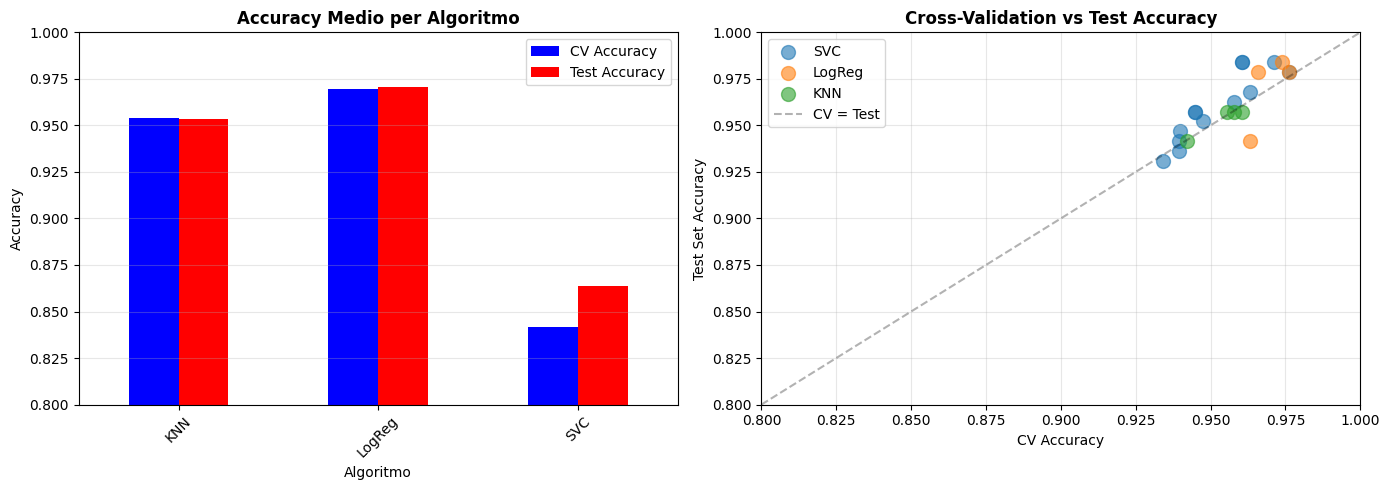

In [22]:

# Crea un grafico comparativo
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Grafico 1: Accuracy medio per algoritmo
model_summary = df_results_sorted.groupby('Model')[['CV Accuracy', 'Test Set Accuracy']].mean()
model_summary.plot(kind='bar', ax=axes[0], color=['blue', 'red'])
axes[0].set_title('Accuracy Medio per Algoritmo', fontsize=12, fontweight='bold')
axes[0].set_ylabel('Accuracy')
axes[0].set_xlabel('Algoritmo')
axes[0].legend(['CV Accuracy', 'Test Accuracy'])
axes[0].set_ylim([0.8, 1.0])
axes[0].grid(axis='y', alpha=0.3)
plt.setp(axes[0].xaxis.get_majorticklabels(), rotation=45)

# Grafico 2: Scatter plot CV vs Test Accuracy
for model_name in df_results_sorted['Model'].unique():
    subset = df_results_sorted[df_results_sorted['Model'] == model_name]
    axes[1].scatter(subset['CV Accuracy'], subset['Test Set Accuracy'], 
                   label=model_name, s=100, alpha=0.6)

# Linea diagonale (CV = Test)
axes[1].plot([0.8, 1.0], [0.8, 1.0], 'k--', alpha=0.3, label='CV = Test')
axes[1].set_xlabel('CV Accuracy')
axes[1].set_ylabel('Test Set Accuracy')
axes[1].set_title('Cross-Validation vs Test Accuracy', fontsize=12, fontweight='bold')
axes[1].legend()
axes[1].grid(alpha=0.3)
axes[1].set_xlim([0.8, 1.0])
axes[1].set_ylim([0.8, 1.0])

plt.tight_layout()
plt.show()


## Conclusioni

### Punti Chiave:

1. **Importanza della Normalizzazione**: I dati sono stati normalizzati con `StandardScaler` perché gli algoritmi SVM e LogisticRegression sono sensibili alla scala delle features. Questo ha risolto i warning di convergenza.

2. **Cross-Validation vs Test Set**: La cross-validation sul training set stima la performance generalization del modello. Se i risultati su test set sono simili a quelli di CV, il modello generalizza bene.

3. **Selezione del Modello**: Il miglior modello è stato selezionato sulla base della CV Accuracy (non sul test set, che dovrebbe rimanere "untouched" per la valutazione finale onesta).

4. **Trade-off Bias-Variance**:
   - **Modelli semplici** (es. KNN con K alto, SVM con C basso): bassa varianza, possibile alto bias
   - **Modelli complessi** (es. KNN con K basso, SVM con C alto): bassa bias, possibile alta varianza

### Risultati Attesi:
- LogisticRegression e SVM di solito ottengono accuracy > 95% su questo dataset
- KNN è competitivo ma potrebbe soffrire di overfitting con K piccoli
- Gap tra CV e Test accuracy dovrebbe essere minimo (< 0.05)
